In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [2]:
DATA_PATH = "..//content/house_prices .csv ppppp.csv"
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (3000, 11)


,area_sqft,bedrooms,bathrooms,floors,age_years,garage_spaces,has_pool,location,condition,distance_to_city_km,price
0,1998,4,3,1,3.0,3,0,Suburban,Poor,14.2,302500
1,1124,2,2,1,40.0,1,0,Downtown,Good,3.8,246100
2,2288,5,5,1,55.0,2,0,Downtown,Good,3.4,508200
3,2411,2,2,2,51.0,1,0,Suburban,Good,9.4,407600
4,532,1,1,3,24.0,2,0,Rural,Good,44.3,79000


In [3]:
df.info()
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   area_sqft            3000 non-null   int64  
 1   bedrooms             3000 non-null   int64  
 2   bathrooms            3000 non-null   int64  
 3   floors               3000 non-null   int64  
 4   age_years            2960 non-null   float64
 5   garage_spaces        3000 non-null   int64  
 6   has_pool             3000 non-null   int64  
 7   location             3000 non-null   object 
 8   condition            3000 non-null   object 
 9   distance_to_city_km  2960 non-null   float64
 10  price                3000 non-null   int64  
dtypes: float64(2), int64(7), object(2)
memory usage: 257.9+ KB


,count,mean,std,min,25%,50%,75%,max
area_sqft,3000.0,1789.843667,640.129209,500.0,1349.0,1800.0,2213.0,3866.0
bedrooms,3000.0,2.610333,1.157990,1.0,2.0,3.0,3.0,7.0
bathrooms,3000.0,2.355333,0.993680,1.0,2.0,2.0,3.0,6.0
floors,3000.0,1.602000,0.655036,1.0,1.0,2.0,2.0,3.0
age_years,2960.0,29.065203,17.408190,0.0,13.0,29.0,44.0,59.0
garage_spaces,3000.0,1.572000,0.802307,0.0,1.0,2.0,2.0,3.0
has_pool,3000.0,0.154667,0.361647,0.0,0.0,0.0,0.0,1.0
distance_to_city_km,2960.0,16.425338,14.846797,0.5,4.9,12.5,19.8,60.0
price,3000.0,335469.233333,145316.735517,22700.0,230700.0,313500.0,421875.0,1106700.0


In [4]:
print("Missing values:\n", df.isna().sum()[df.isna().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
# Missing values are handled inside the pipeline (median imputation) to avoid data leakage.

Missing values:
 age_years              40
distance_to_city_km    40
dtype: int64

Duplicate rows: 0


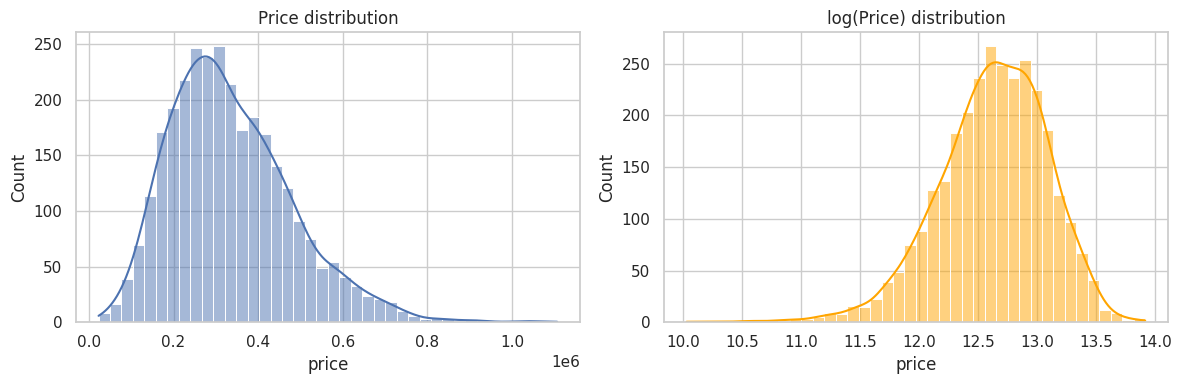

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price"], bins=40, kde=True, ax=ax[0]); ax[0].set_title("Price distribution")
sns.histplot(np.log1p(df["price"]), bins=40, kde=True, ax=ax[1], color="orange"); ax[1].set_title("log(Price) distribution")
plt.tight_layout(); plt.show()

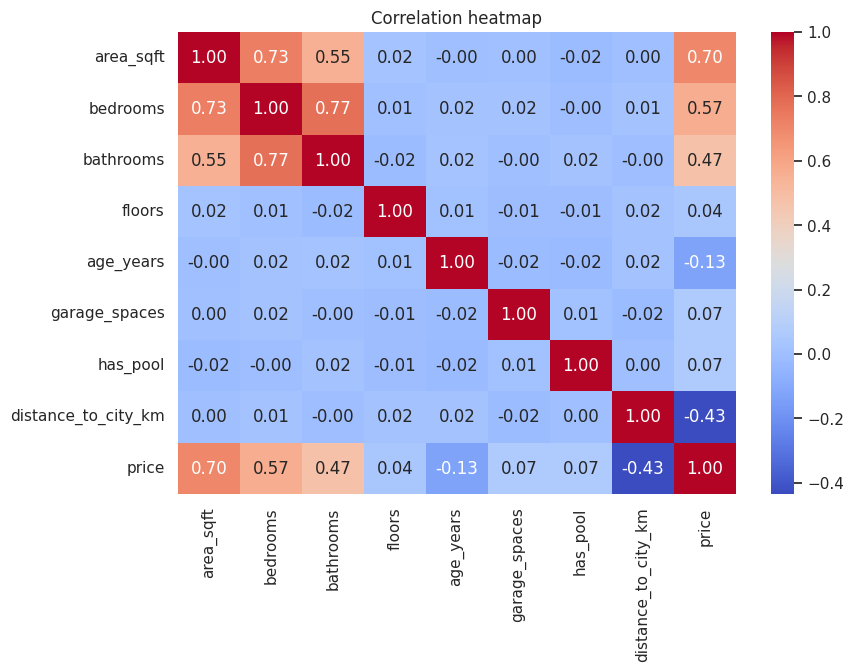

In [6]:
plt.figure(figsize=(9, 6))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation heatmap"); plt.show()

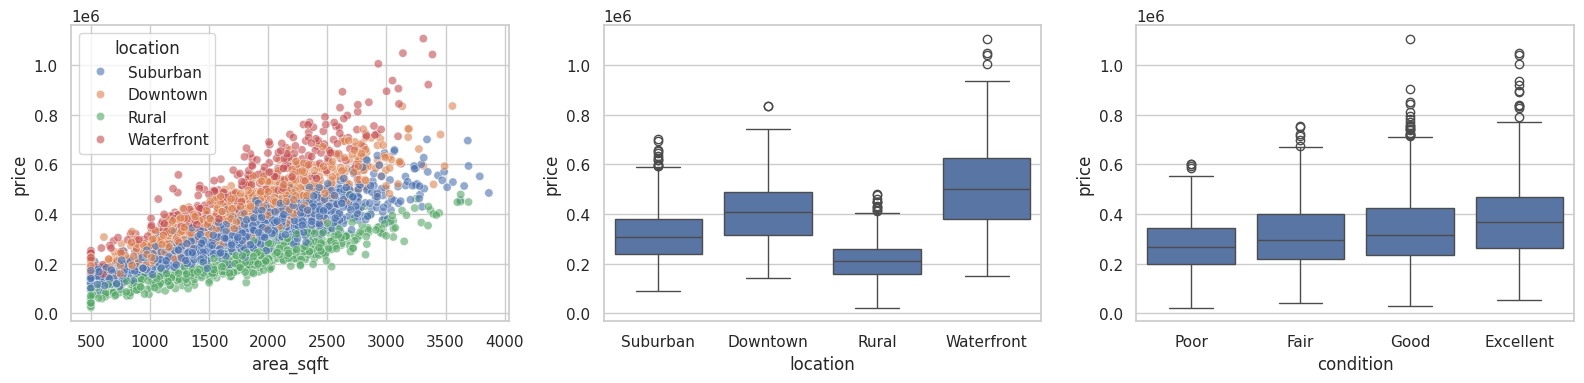

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(data=df, x="area_sqft", y="price", hue="location", alpha=.6, ax=ax[0])
sns.boxplot(data=df, x="location", y="price", ax=ax[1])
sns.boxplot(data=df, x="condition", y="price", order=["Poor","Fair","Good","Excellent"], ax=ax[2])
plt.tight_layout(); plt.show()

In [8]:
X = df.drop(columns="price")
y = df["price"]

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print("Numeric:", num_cols); print("Categorical:", cat_cols)

preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)

Numeric: ['area_sqft', 'bedrooms', 'bathrooms', 'floors', 'age_years', 'garage_spaces', 'has_pool', 'distance_to_city_km']
Categorical: ['location', 'condition']
(2400, 10) (600, 10)


In [9]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    cv = cross_val_score(pipe, X_train, y_train, cv=5, scoring="r2").mean()
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    rows.append({"Model": name, "CV R2": cv,
                 "Test R2": r2_score(y_test, pred),
                 "MAE": mean_absolute_error(y_test, pred),
                 "RMSE": np.sqrt(mean_squared_error(y_test, pred))})

results = pd.DataFrame(rows).sort_values("Test R2", ascending=False).reset_index(drop=True)
results.round(3)

,Model,CV R2,Test R2,MAE,RMSE
0,Gradient Boosting,0.963,0.967,19360.194,25787.976
1,Random Forest,0.946,0.950,24284.307,31866.074
2,Ridge,0.937,0.933,26966.755,36671.137
3,Linear Regression,0.937,0.933,26969.608,36676.287


In [10]:
gb_pipe = Pipeline([("prep", preprocess),
                    ("model", GradientBoostingRegressor(random_state=RANDOM_STATE))])

param_dist = {
    "model__n_estimators": [200, 300, 500],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_depth": [2, 3, 4],
    "model__subsample": [0.7, 0.85, 1.0],
}
search = RandomizedSearchCV(gb_pipe, param_dist, n_iter=15, cv=5, scoring="r2",
                            random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X_train, y_train)
print("Best params:", search.best_params_)
print("Best CV R2 :", round(search.best_score_, 4))
best_model = search.best_estimator_

Best params: {'model__subsample': 1.0, 'model__n_estimators': 300, 'model__max_depth': 3, 'model__learning_rate': 0.1}
Best CV R2 : 0.9663


R²   : 0.9692
MAE  : $18,704
RMSE : $24,947


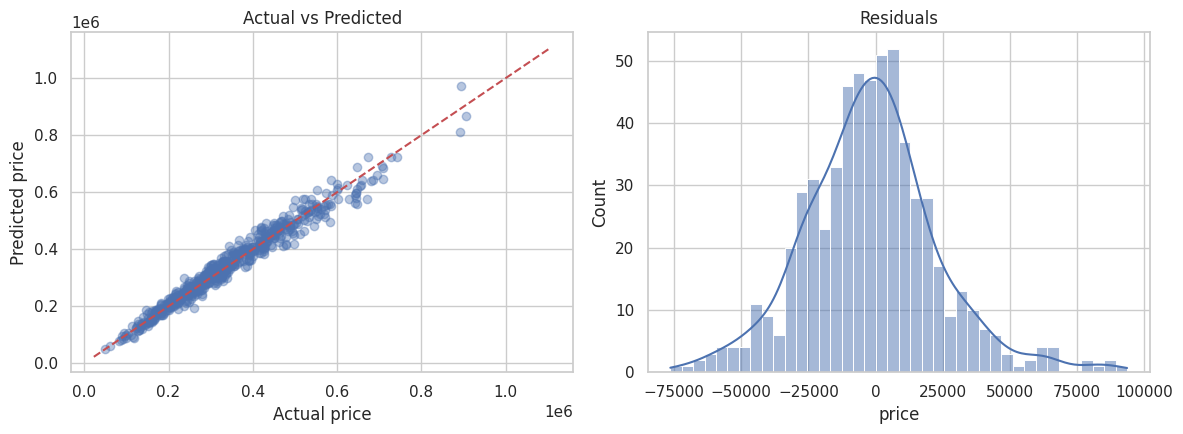

In [11]:
pred = best_model.predict(X_test)
print(f"R²   : {r2_score(y_test, pred):.4f}")
print(f"MAE  : ${mean_absolute_error(y_test, pred):,.0f}")
print(f"RMSE : ${np.sqrt(mean_squared_error(y_test, pred)):,.0f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(y_test, pred, alpha=.4)
ax[0].plot([y.min(), y.max()], [y.min(), y.max()], "r--")
ax[0].set_xlabel("Actual price"); ax[0].set_ylabel("Predicted price"); ax[0].set_title("Actual vs Predicted")
sns.histplot(y_test - pred, bins=40, kde=True, ax=ax[1]); ax[1].set_title("Residuals")
plt.tight_layout(); plt.show()

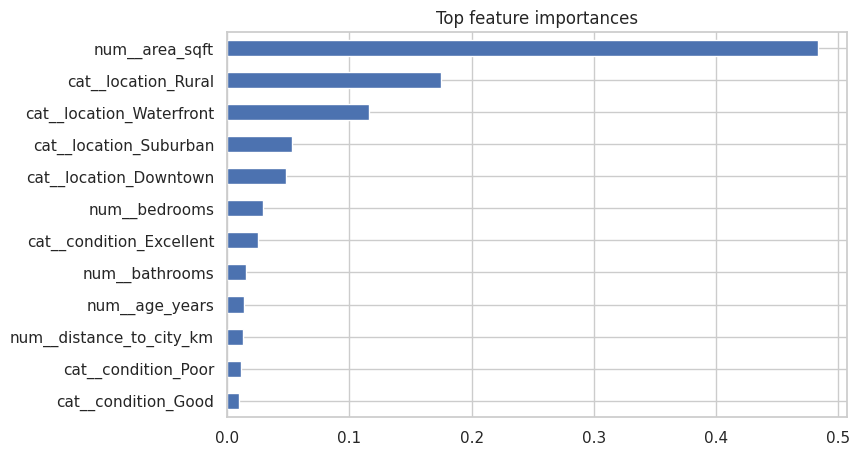

In [12]:
# Feature importance
feat_names = best_model.named_steps["prep"].get_feature_names_out()
imp = pd.Series(best_model.named_steps["model"].feature_importances_, index=feat_names).sort_values()
imp.tail(12).plot(kind="barh", figsize=(8, 5), title="Top feature importances"); plt.show()

In [13]:
import os
os.makedirs("../models", exist_ok=True)
joblib.dump(best_model, "../models/house_price_model.pkl")
print("Model saved ✔  -> ../models/house_price_model.pkl")

Model saved ✔  -> ../models/house_price_model.pkl


In [14]:
model = joblib.load("../models/house_price_model.pkl")
new_house = pd.DataFrame([{
    "area_sqft": 2200, "bedrooms": 4, "bathrooms": 3, "floors": 2, "age_years": 8,
    "garage_spaces": 2, "has_pool": 0, "location": "Suburban",
    "condition": "Good", "distance_to_city_km": 12.0,
}])
print(f"Predicted price: ${model.predict(new_house)[0]:,.0f}")

Predicted price: $412,695
